<table><tr>
<td><img src="logo_instituto57.png" width="120"></td>
<td style="text-align:center"><h1>Proyecto de Análisis y Exploración de Datos</h1>Estaciones de servicio y precios de combustibles en Argentina – Metodología CRISP-DM</td>
<td><img src="logo_ypf.png" width="120"></td>
</tr></table>

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
sns.set_theme(style='whitegrid')

LOGO_INST, LOGO_YPF = 'logo_instituto57.png', 'logo_ypf.png'
LOGOS_BANDERA = {'YPF':'ypf','SHELL C.A.P.S.A.':'shell','AXION':'axion','PUMA':'puma','BLANCA':'blanca',
                 'DAPSA S.A.':'dapsa','GULF':'gulf','REFINOR':'refinor','VOY':'voy'}

def poner_logo(ax, archivo, xy, zoom=0.17):
    if os.path.exists(archivo):
        ax.add_artist(AnnotationBbox(OffsetImage(mpimg.imread(archivo), zoom=zoom), xy, xycoords='axes fraction', frameon=False))

def marca(ax):
    poner_logo(ax, LOGO_INST, (0.05, 1.17), 0.07); poner_logo(ax, LOGO_YPF, (0.95, 1.17), 0.3)

def barras_con_logos(serie, titulo, color='#1f6fbf'):
    s = serie.sort_values()
    fig, ax = plt.subplots(figsize=(10,5.5))
    ax.barh(s.index, s.values, color=color)
    for i, b in enumerate(s.index):
        f = f'logos/{LOGOS_BANDERA.get(b, "")}.png'
        if os.path.exists(f):
            ax.add_artist(AnnotationBbox(OffsetImage(mpimg.imread(f), zoom=0.2), (-0.40, i), xycoords=('axes fraction','data'), frameon=False))
        ax.text(s.values[i], i, f'  {s.values[i]:,.0f}', va='center')
    ax.set_title(titulo); fig.subplots_adjust(left=0.45); marca(ax); plt.show()

# 1. Comprensión del negocio
**Situación:** el mercado de venta minorista de combustibles en Argentina está compuesto por miles de estaciones agrupadas en *banderas* (YPF, Shell, Axion, Puma, etc.). La Secretaría de Energía publica los precios en surtidor (Res. 314/2016).

**Objetivos del negocio:**
- Conocer cómo se reparte el mercado entre banderas y regiones.
- Entender qué factores (bandera, región, provincia) se asocian a que una estación venda más caro o más barato.

**Objetivos de explotación de datos (técnicos):**
- Describir la participación de cada bandera y su distribución regional (dashboard en Power BI).
- Construir un **árbol de decisión** que clasifique una estación como *Cara* o *Barata* (respecto de la mediana de su mes) según su bandera y ubicación.

**Criterio de éxito:** que el árbol supere claramente al clasificador de referencia (siempre predecir la clase más frecuente) y que sus reglas sean interpretables.

**Recursos y riesgos:** Python/Jupyter, Power BI y el CSV oficial. Riesgos: datos faltantes, precios mal cargados y meses con pocos registros (plan: limpieza y filtros).

# 2. Comprensión de los datos

In [2]:
RUTA = 'precios-en-surtidor-resolucin-3142016.csv'
df = pd.read_csv(RUTA, sep=';', low_memory=False)   # el archivo usa ';' como separador
print('Filas y columnas:', df.shape)
df.head(3)

Filas y columnas: (36669, 19)


,indice_tiempo,idempresa,cuit,empresa,direccion,localidad,provincia,region,idproducto,producto,idtipohorario,tipohorario,precio,fecha_vigencia,idempresabandera,empresabandera,latitud,longitud,geojson
0,2026-05,1376,33-64337382-9,10 DE SETIEMBRE S.A.,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,PAMPEANA,19.0,Gas Oil Grado 2,2.0,Diurno,2190,01/05/2026 12:43,28.0,PUMA,-34.658.476,-58.529.443,"{""type"":""Point"",""coordinates"":[-58.529443,-34...."
1,2026-05,1376,33-64337382-9,10 DE SETIEMBRE S.A.,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,PAMPEANA,19.0,Gas Oil Grado 2,3.0,Nocturno,2190,01/05/2026 12:43,28.0,PUMA,-34.658.476,-58.529.443,"{""type"":""Point"",""coordinates"":[-58.529443,-34...."
2,2026-05,1376,33-64337382-9,10 DE SETIEMBRE S.A.,Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,PAMPEANA,21.0,Gas Oil Grado 3,2.0,Diurno,2478,01/05/2026 12:44,28.0,PUMA,-34.658.476,-58.529.443,"{""type"":""Point"",""coordinates"":[-58.529443,-34...."


In [3]:
df.info()
nulos = df.isna().sum()
print('\nColumnas con nulos:\n', nulos[nulos>0])
print('\nPeríodo:', df['indice_tiempo'].min(), '→', df['indice_tiempo'].max())
print('\nProductos:\n', df['producto'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 36669 entries, 0 to 36668
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   indice_tiempo     36669 non-null  str    
 1   idempresa         36669 non-null  int64  
 2   cuit              36669 non-null  str    
 3   empresa           36661 non-null  str    
 4   direccion         36661 non-null  str    
 5   localidad         36661 non-null  str    
 6   provincia         36661 non-null  str    
 7   region            28706 non-null  str    
 8   idproducto        36661 non-null  float64
 9   producto          36661 non-null  str    
 10  idtipohorario     36661 non-null  float64
 11  tipohorario       36661 non-null  str    
 12  precio            36661 non-null  str    
 13  fecha_vigencia    36661 non-null  str    
 14  idempresabandera  36661 non-null  float64
 15  empresabandera    36661 non-null  str    
 16  latitud           36643 non-null  str    
 17  long

**Verificación de calidad (hallazgos):** `precio` viene como texto; 8 filas sin empresa/producto; 7.963 filas sin `region`; hay precios menores a $50 (errores de carga) y banderas casi sin registros (`WICO`, `SIN EMPRESA BANDERA`).

# 3. Preparación de los datos
- **Selección:** se excluyen `WICO` y `SIN EMPRESA BANDERA` (menos de 15 registros).
- **Limpieza:** `precio` a numérico, se eliminan nulos, duplicados y precios < $50.
- **Construcción:** se completa `region` a partir de la provincia más frecuente; se crea la columna `fecha`.
- **Cambio de formato:** `indice_tiempo` (texto AAAA-MM) → fecha.

In [4]:
df['precio'] = pd.to_numeric(df['precio'], errors='coerce')
df['fecha'] = pd.to_datetime(df['indice_tiempo'], format='%Y-%m')
df = df.dropna(subset=['precio','empresabandera','producto'])
df = df[(df['precio'] > 50) & (~df['empresabandera'].isin(['SIN EMPRESA BANDERA','WICO']))].drop_duplicates()

mapa = df.dropna(subset=['region']).groupby('provincia')['region'].agg(lambda s: s.mode()[0])
df['region'] = df['region'].fillna(df['provincia'].map(mapa))
print('Filas finales:', df.shape[0], '| nulos en región:', df['region'].isna().sum())

Filas finales: 35268 | nulos en región: 0


## 3.1 Exploración: lo que muestra el dashboard de Power BI

Mes: 2026-09 | registros: 837 | estaciones: 199 | precio promedio: $2072.48 | banderas: 8


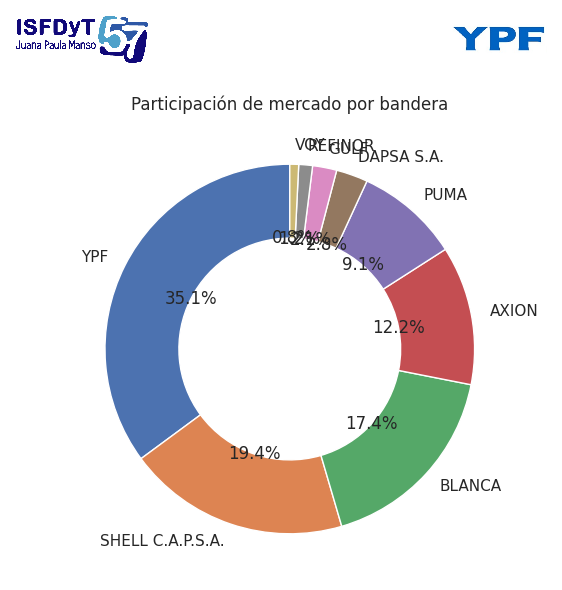

In [5]:
ult = df['fecha'].max()
d = df[df['fecha']==ult]
print('Mes:', ult.strftime('%Y-%m'), '| registros:', len(d), '| estaciones:', d['idempresa'].nunique(), '| precio promedio: $%.2f' % d['precio'].mean(), '| banderas:', d['empresabandera'].nunique())

part = df.groupby('empresabandera')['idempresa'].nunique().sort_values(ascending=False)
plt.figure(figsize=(6,6))
plt.pie(part, labels=part.index, autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.4))
plt.title('Participación de mercado por bandera'); marca(plt.gca()); plt.show()

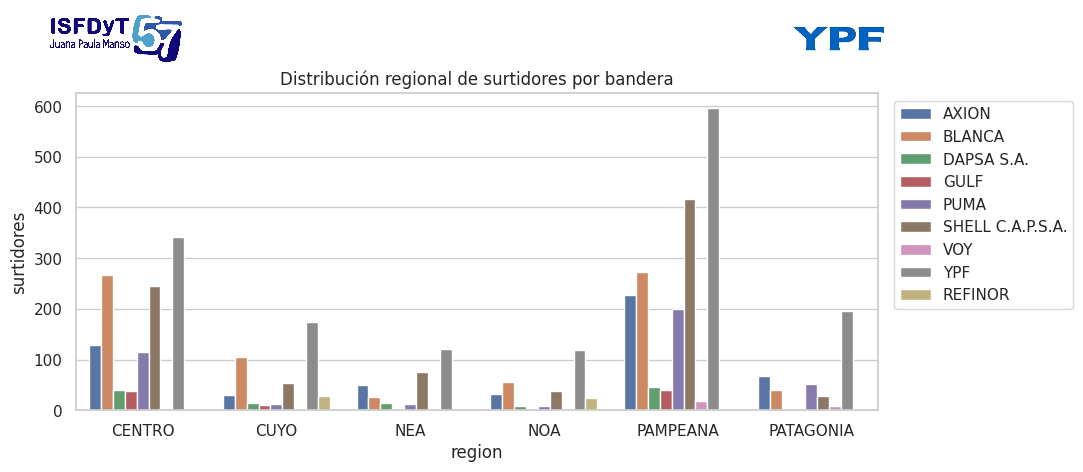

In [6]:
reg = df.groupby(['region','empresabandera'])['idempresa'].nunique().reset_index(name='surtidores')
plt.figure(figsize=(11,5))
sns.barplot(data=reg, x='region', y='surtidores', hue='empresabandera')
plt.title('Distribución regional de surtidores por bandera')
plt.legend(bbox_to_anchor=(1.01,1), loc='upper left'); marca(plt.gca()); plt.tight_layout(); plt.show()

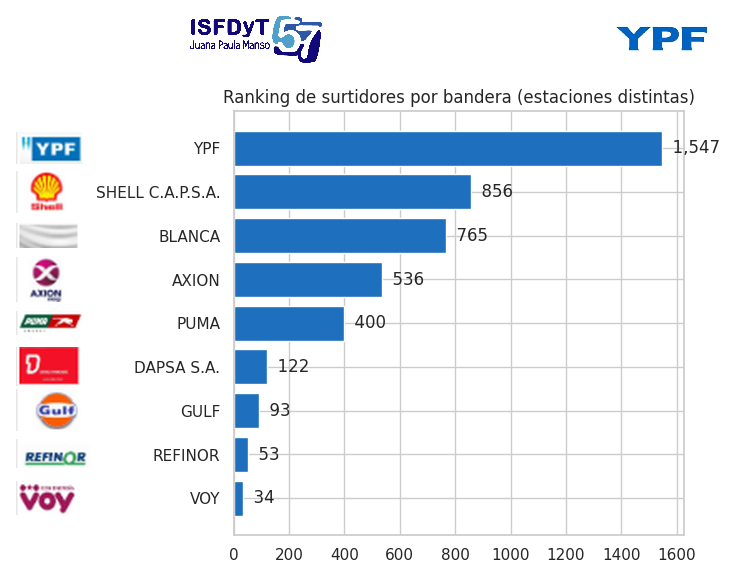

In [7]:
barras_con_logos(part, 'Ranking de surtidores por bandera (estaciones distintas)')

# 4. Modelado
## 4.1 Selección de la técnica: árbol de decisión (clasificación)
**Por qué:** la variable a predecir es una categoría (*Caro* / *Barato*) y las variables explicativas son categóricas (bandera, región, provincia). Un árbol maneja bien este tipo de datos y, sobre todo, **produce reglas "si... entonces" fáciles de interpretar**, lo que permite explicar el resultado a personas sin formación técnica.

**Teoría:** un árbol de decisión divide los datos de forma recursiva. En cada nodo elige la pregunta (variable y umbral) que mejor separa las clases, medido con una impureza como el **índice de Gini** (1 − Σpᵢ²; vale 0 cuando el nodo es puro). Repite el proceso en cada rama hasta alcanzar un criterio de parada (profundidad máxima, mínimo de muestras por hoja). Cada hoja predice la clase mayoritaria de sus registros. Si crece sin límite memoriza los datos de entrenamiento (*sobreajuste*), por eso se limita la profundidad y se valida con datos no vistos.

**Variable objetivo:** precio de la nafta súper (turno diurno, últimos 12 meses) clasificado como *Caro* si supera la mediana de ese mes y *Barato* si no. Compararlo contra la mediana **del mismo mes** elimina el efecto de la inflación.
**Variables explicativas:** bandera, región y provincia.

In [8]:
prod = 'Nafta (súper) entre 92 y 95 Ron'
d = df[(df['producto']==prod) & (df['tipohorario']=='Diurno') & (df['fecha'] >= ult - pd.DateOffset(months=11))].copy()
d['categoria'] = np.where(d['precio'] > d.groupby('fecha')['precio'].transform('median'), 'Caro', 'Barato')
print(len(d), 'registros')
print(d['categoria'].value_counts(normalize=True).round(3))

X = pd.get_dummies(d[['empresabandera','region','provincia']])   # variables categóricas → 0/1
y = d['categoria']
X.shape

1226 registros
categoria
Barato    0.546
Caro      0.454
Name: proportion, dtype: float64


(1226, 39)

## 4.2 Diseño de pruebas
Se separa 70 % de los datos para entrenar y 30 % para probar (los grupos mantienen la proporción de Caro/Barato). Para elegir la profundidad del árbol se usa validación cruzada de 5 particiones sólo sobre el conjunto de entrenamiento. Como referencia se usa un clasificador que siempre responde la clase más frecuente.

Referencia (clase más frecuente): exactitud = 0.546


             exactitud_cv
profundidad              
2                   0.569
3                   0.613
4                   0.622
5                   0.633
6                   0.651
8                   0.649
10                  0.655


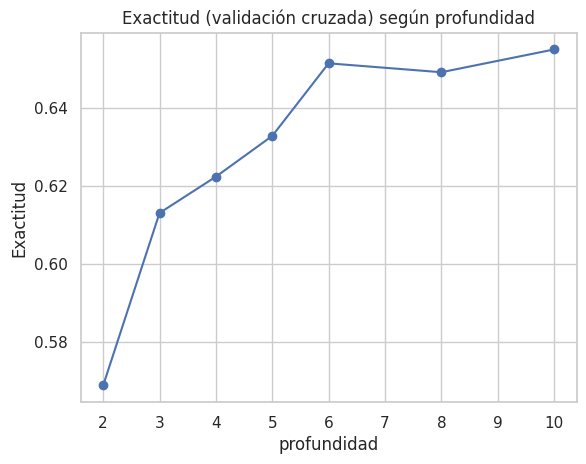

In [9]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
base = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
print('Referencia (clase más frecuente): exactitud = %.3f' % base.score(Xte, yte))

res = []
for prof in [2, 3, 4, 5, 6, 8, 10]:
    m = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=10, random_state=42)
    res.append((prof, cross_val_score(m, Xtr, ytr, cv=5).mean()))
res = pd.DataFrame(res, columns=['profundidad','exactitud_cv']).set_index('profundidad')
print(res.round(3))
res.plot(marker='o', title='Exactitud (validación cruzada) según profundidad', legend=False)
plt.ylabel('Exactitud'); plt.show()

## 4.3 Construcción del modelo
Se elige una profundidad moderada: a partir de cierto punto la exactitud casi no mejora y el árbol se vuelve difícil de leer (se prioriza la interpretabilidad).

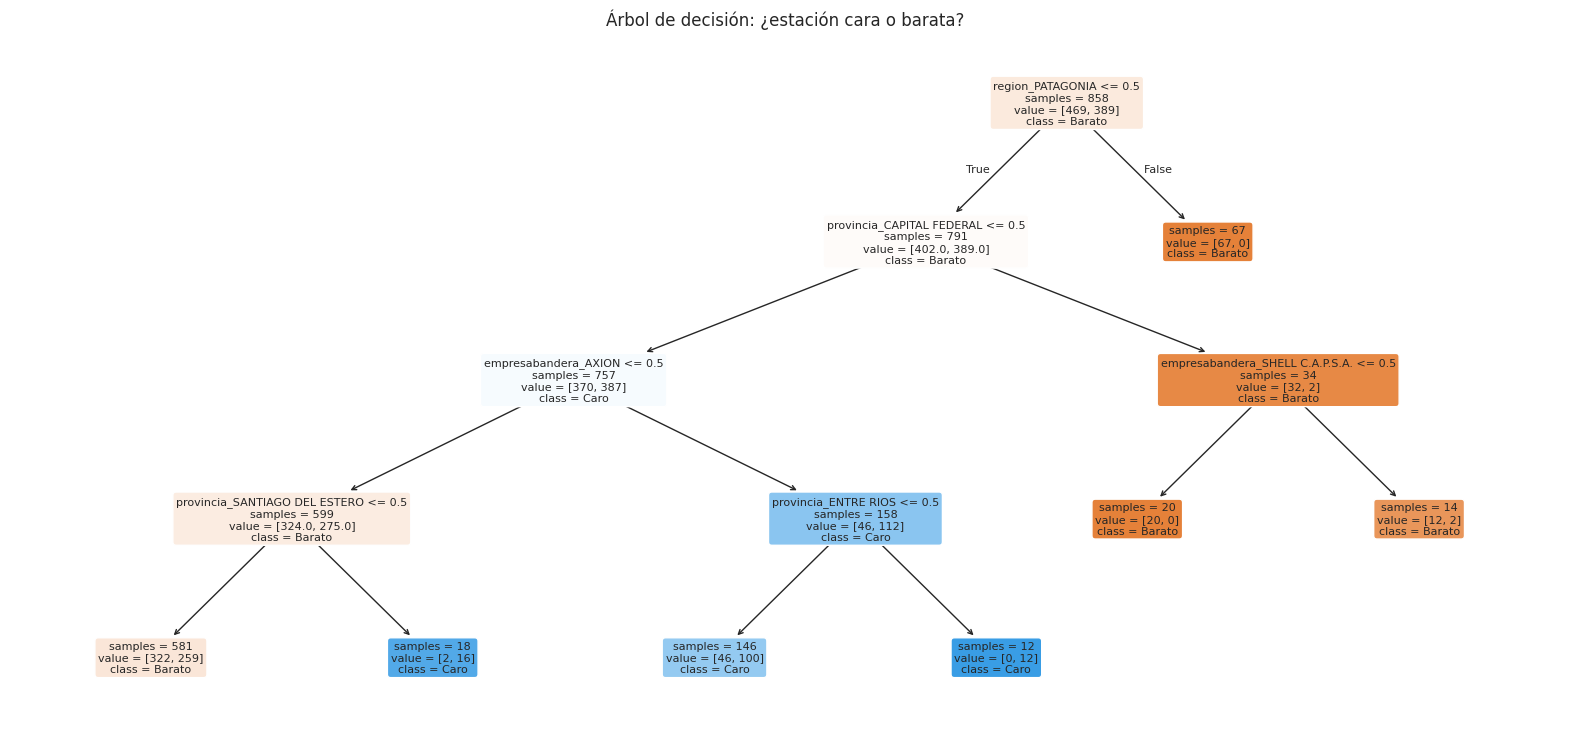

In [10]:
PROFUNDIDAD = 4      # podés cambiarla según el gráfico anterior
arbol = DecisionTreeClassifier(max_depth=PROFUNDIDAD, min_samples_leaf=10, random_state=42).fit(Xtr, ytr)

plt.figure(figsize=(20,9))
plot_tree(arbol, feature_names=X.columns, class_names=arbol.classes_, filled=True, rounded=True, fontsize=8, impurity=False)
plt.title('Árbol de decisión: ¿estación cara o barata?'); plt.show()

In [11]:
print(export_text(arbol, feature_names=list(X.columns), max_depth=3))

|--- region_PATAGONIA <= 0.50
|   |--- provincia_CAPITAL FEDERAL <= 0.50
|   |   |--- empresabandera_AXION <= 0.50
|   |   |   |--- provincia_SANTIAGO DEL ESTERO <= 0.50
|   |   |   |   |--- class: Barato
|   |   |   |--- provincia_SANTIAGO DEL ESTERO >  0.50
|   |   |   |   |--- class: Caro
|   |   |--- empresabandera_AXION >  0.50
|   |   |   |--- provincia_ENTRE RIOS <= 0.50
|   |   |   |   |--- class: Caro
|   |   |   |--- provincia_ENTRE RIOS >  0.50
|   |   |   |   |--- class: Caro
|   |--- provincia_CAPITAL FEDERAL >  0.50
|   |   |--- empresabandera_SHELL C.A.P.S.A. <= 0.50
|   |   |   |--- class: Barato
|   |   |--- empresabandera_SHELL C.A.P.S.A. >  0.50
|   |   |   |--- class: Barato
|--- region_PATAGONIA >  0.50
|   |--- class: Barato



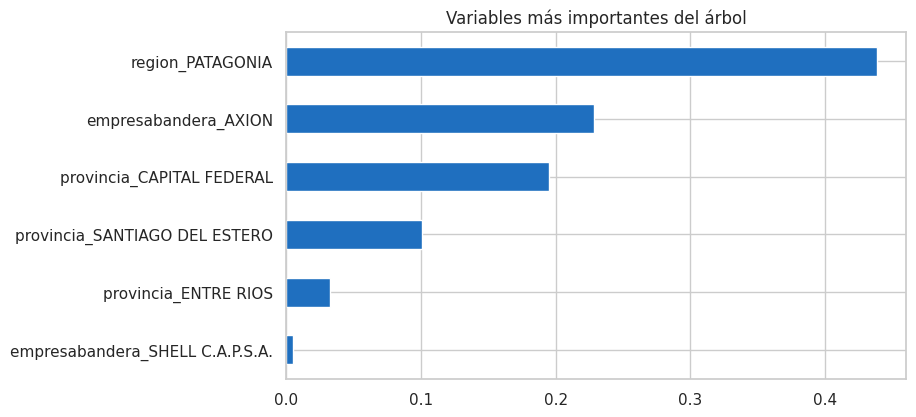

In [12]:
imp = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
imp = imp[imp>0].head(10)
imp.sort_values().plot(kind='barh', figsize=(8,4.5), color='#1f6fbf', title='Variables más importantes del árbol')
plt.show()

## 4.4 Evaluación del modelo

Exactitud en prueba: 0.663  (referencia: 0.546)
Exactitud en entrenamiento: 0.640

              precision    recall  f1-score   support

      Barato       0.64      0.89      0.74       201
        Caro       0.75      0.39      0.51       167

    accuracy                           0.66       368
   macro avg       0.69      0.64      0.63       368
weighted avg       0.69      0.66      0.64       368



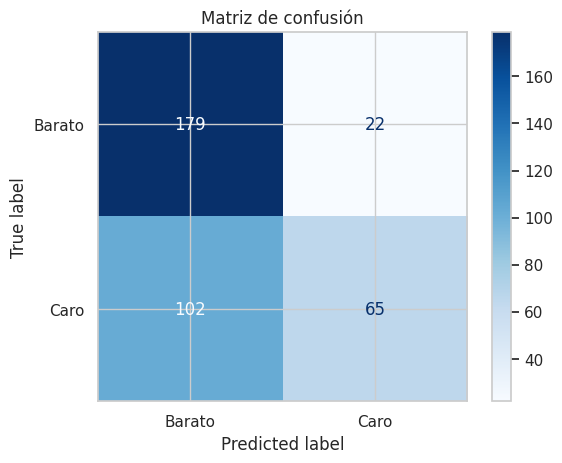

In [13]:
pred = arbol.predict(Xte)
print('Exactitud en prueba: %.3f  (referencia: %.3f)' % (accuracy_score(yte, pred), base.score(Xte, yte)))
print('Exactitud en entrenamiento: %.3f' % arbol.score(Xtr, ytr))
print()
print(classification_report(yte, pred))
ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=arbol.classes_), display_labels=arbol.classes_).plot(cmap='Blues')
plt.title('Matriz de confusión'); plt.show()

# 5. Evaluación
**Evaluación de resultados:** completá con tus palabras al ver los resultados de arriba. Guía:
- ¿Cuánto mejora el árbol respecto de la referencia? ¿Cumple el criterio de éxito de la fase 1?
- ¿Qué variables aparecen primero en el árbol (bandera, región, provincia)? ¿Qué reglas se pueden leer?
- ¿Qué indica la matriz de confusión (en qué clase se equivoca más)?
- ¿Coincide con los *insights* del dashboard (predominio de YPF, Pampeana con más surtidores, mercado concentrado)?

**Revisión del proceso / limitaciones:**
- El modelo sólo usa bandera y ubicación; el precio depende también de impuestos locales, costos logísticos y tipo de estación, que no están en el dataset, por eso no se espera una exactitud muy alta.
- El dataset guarda la última actualización de cada estación, por lo que algunos meses tienen pocos registros.
- Contar *estaciones distintas* o *registros* da participaciones distintas.
- Los precios son nominales (se compararon dentro de cada mes para neutralizar la inflación).

**Próximas etapas / sugerencias:**
- Agregar variables (localidad, tipo de zona, cercanía a refinerías, impuestos provinciales).
- Probar otros modelos (bosques aleatorios) y comparar.
- Predecir también otros combustibles (gasoil, premium).
- Analizar la evolución en el tiempo ajustando por IPC.